In [1]:
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

print("Dataset uploaded successfully!")

Saving sms+spam+collection.zip to sms+spam+collection.zip
Dataset uploaded successfully!


In [3]:
import io

filename = next(iter(uploaded))

df = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("Dataset shape:", df.shape)
display(df.head())

print("\nClass distribution:")
print(df["label"].value_counts())

UnicodeDecodeError: 'utf-8' codec can't decode byte 0x81 in position 10: invalid start byte

In [4]:
print(list(uploaded.keys()))

['sms+spam+collection.zip']


In [7]:
import pandas as pd
import io
import zipfile

filename = next(iter(uploaded))
file_bytes = uploaded[filename]

# Open the ZIP archive and extract the target dataset file
with zipfile.ZipFile(io.BytesIO(file_bytes)) as z:
    # Read 'SMSSpamCollection' directly from the zip archive
    with z.open('SMSSpamCollection') as f:
        df = pd.read_csv(
            f,
            sep="\t",
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

print("\nClass distribution:")
print(df["label"].value_counts())

Dataset loaded successfully!
Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [8]:
# Step 5: Data preprocessing

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Remove missing and duplicate rows
df = df.dropna()
df = df.drop_duplicates()

# Convert labels into numbers
df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print("\nDataset after cleaning:", df.shape)
print("\nLabel distribution:")
print(df["label"].value_counts())

# Display sample messages
display(df[["label", "message"]].head())

Missing values:
label      0
message    0
dtype: int64

Dataset after cleaning: (5169, 3)

Label distribution:
label
ham     4516
spam     653
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [9]:
# Step 6: Split dataset into train, validation and test

X = df["message"]
y = df["label_num"]

# First: 80% training, 20% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split remaining 20% into 10% validation and 10% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))
print("Total samples:", len(X_train) + len(X_val) + len(X_test))

Training samples: 4135
Validation samples: 517
Testing samples: 517
Total samples: 5169


In [10]:
# Step 7: Convert text into numerical features using TF-IDF

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=3000
)

# Learn vocabulary from training data only
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation and test data
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Feature Extraction Completed!")
print("Training feature shape:", X_train_tfidf.shape)
print("Validation feature shape:", X_val_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))

TF-IDF Feature Extraction Completed!
Training feature shape: (4135, 3000)
Validation feature shape: (517, 3000)
Testing feature shape: (517, 3000)
Number of features: 3000


In [11]:
# Step 8: Train three classification models

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42, class_weight="balanced"
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": LinearSVC(
        random_state=42, class_weight="balanced"
    )
}

for name, model in models.items():
    start_time = time.time()
    model.fit(X_train_tfidf, y_train)
    elapsed = time.time() - start_time

    print(f"{name} trained successfully!")
    print(f"Training time: {elapsed:.3f} seconds\n")

Decision Tree trained successfully!
Training time: 0.443 seconds

KNN trained successfully!
Training time: 0.002 seconds

SVM trained successfully!
Training time: 0.012 seconds



In [12]:
# Step 9: Evaluate models on validation data

results = []

for name, model in models.items():
    y_pred = model.predict(X_val_tfidf)

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_pred, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Algorithm,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.9400,0.7397,0.8182,0.7770
1,KNN,0.9052,1.0000,0.2576,0.4096
2,SVM,0.9729,0.9062,0.8788,0.8923


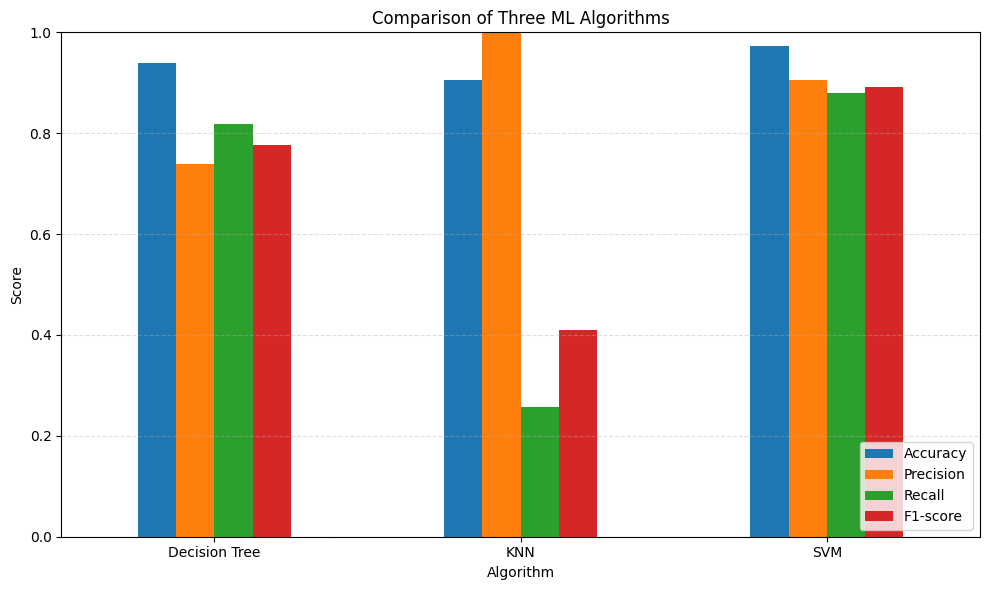

In [13]:


# Step 10: Compare the three algorithms visually

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

results_df.plot(
    x="Algorithm",
    y=metrics,
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Comparison of Three ML Algorithms")
plt.ylabel("Score")
plt.xlabel("Algorithm")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

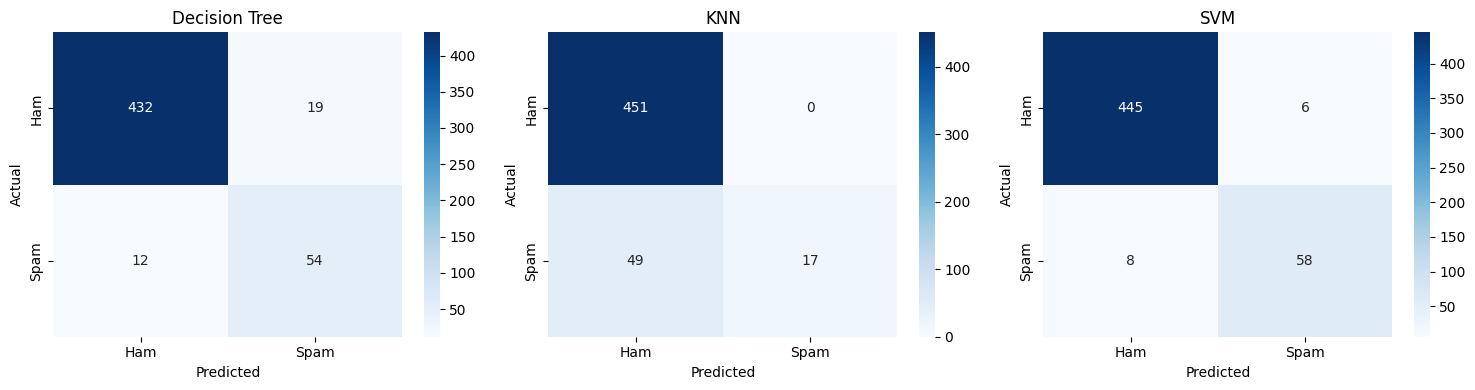

In [14]:
# Step 11: Confusion matrix for each model

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_val_tfidf)
    cm = confusion_matrix(y_val, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

,K Value,Accuracy,Precision,Recall,F1-score
0,3,0.9246,1.0,0.4091,0.5806
1,5,0.9052,1.0,0.2576,0.4096
2,7,0.8975,1.0,0.1970,0.3291
3,9,0.8917,1.0,0.1515,0.2632


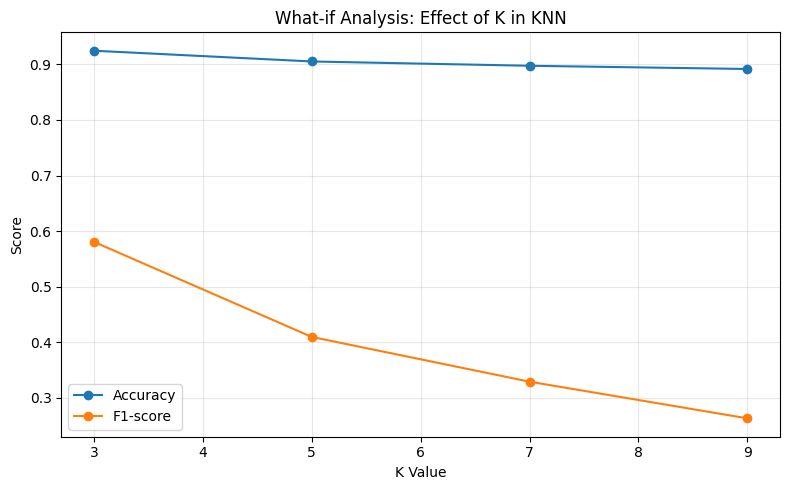

In [15]:
# Step 12: What-if analysis with different K values

knn_results = []

for k in [3, 5, 7, 9]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_tfidf, y_train)

    pred = knn.predict(X_val_tfidf)

    knn_results.append({
        "K Value": k,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(
            y_val, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, pred, zero_division=0
        )
    })

knn_results_df = pd.DataFrame(knn_results)
display(knn_results_df.round(4))

knn_results_df.plot(
    x="K Value",
    y=["Accuracy", "F1-score"],
    marker="o",
    figsize=(8, 5)
)

plt.title("What-if Analysis: Effect of K in KNN")
plt.ylabel("Score")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# Step 13: Final evaluation on unseen test data

final_results = []

for name, model in models.items():
    start_time = time.time()

    # Predict using the untouched test dataset
    y_test_pred = model.predict(X_test_tfidf)

    test_time = time.time() - start_time

    final_results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(
            y_test, y_test_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_test_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_test_pred, zero_division=0
        ),
        "Prediction Time (sec)": round(test_time, 4)
    })

final_results_df = pd.DataFrame(final_results)

print("FINAL TEST RESULTS")
display(final_results_df.round(4))

FINAL TEST RESULTS


,Algorithm,Accuracy,Precision,Recall,F1-score,Prediction Time (sec)
0,Decision Tree,0.9478,0.7639,0.8462,0.8029,0.0041
1,KNN,0.9033,0.9412,0.2462,0.3902,0.1008
2,SVM,0.9807,0.9365,0.9077,0.9219,0.0004


In [17]:
# Select the model with the highest test F1-score
best_index = final_results_df["F1-score"].idxmax()
best_model_name = final_results_df.loc[best_index, "Algorithm"]
best_model = models[best_model_name]

print("Best model:", best_model_name)
print(
    "Best test F1-score:",
    round(final_results_df.loc[best_index, "F1-score"], 4)
)

Best model: SVM
Best test F1-score: 0.9219


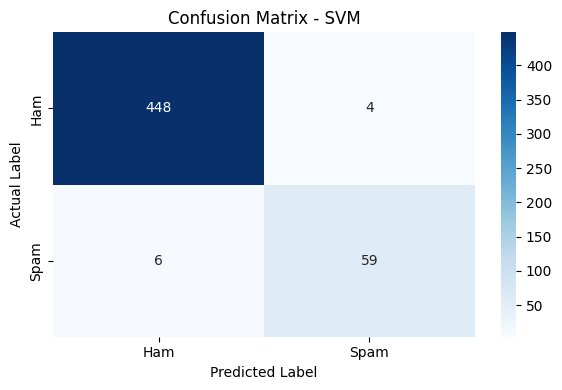


Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       452
        Spam       0.94      0.91      0.92        65

    accuracy                           0.98       517
   macro avg       0.96      0.95      0.96       517
weighted avg       0.98      0.98      0.98       517



In [18]:
# Confusion matrix for the selected model

best_test_pred = best_model.predict(X_test_tfidf)

cm = confusion_matrix(y_test, best_test_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_test_pred,
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

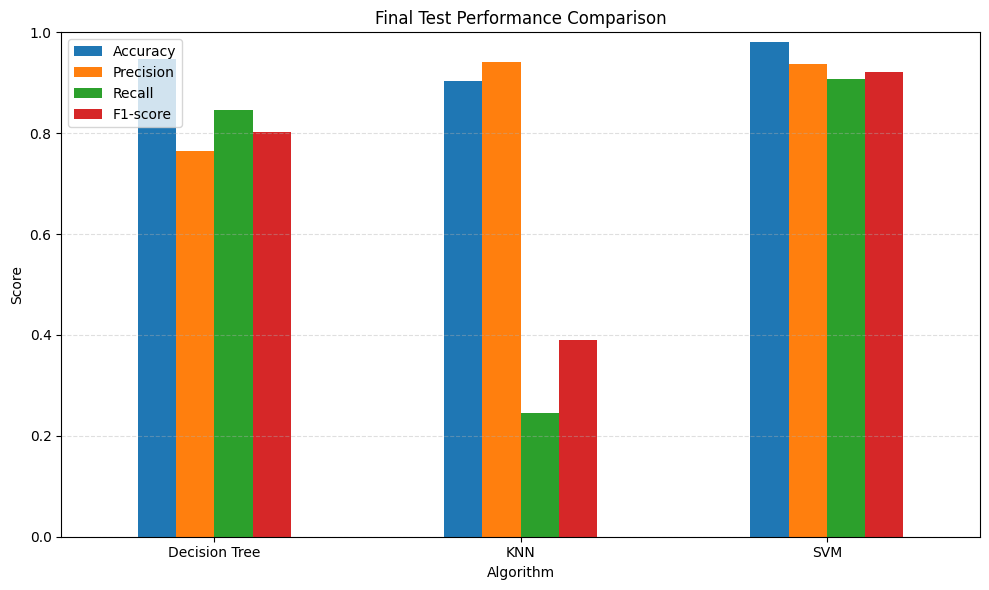

In [19]:
# Final test performance comparison

final_results_df.plot(
    x="Algorithm",
    y=["Accuracy", "Precision", "Recall", "F1-score"],
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Final Test Performance Comparison")
plt.ylabel("Score")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()